Q7 et Q8 : identifier les types de terroir et définir le cahier de culture
Projet Datamining, Sujet 6 : Domaine des Trois Rivières

Les deux questions
Q7. Les parcelles sont conduites de la même façon depuis trente ans. Combien de types de terroir a-t-on en réalité sur le domaine ?
Q8. Pour chaque type, quelle conduite — densité, apports, traitements ? C'est ce qu'on veut écrire dans le cahier de culture.
Démarche
Explorer les variables naturelles du domaine (altitude, pente, pluviométrie, sol, exposition) et traiter les valeurs manquantes avant de regrouper les parcelles.
Standardiser les variables numériques du terroir et tester plusieurs découpages avec k-means (méthode du coude et score de silhouette) pour choisir le nombre de terroirs.
Décrire le profil de chaque terroir (valeurs d'origine, sols, expositions, rendement et part de premium) et sauvegarder le résultat (parcelles_terroirs.csv).
Analyser les pratiques de conduite (densité, azote, traitements) dans chaque terroir sur les 217 parcelles valides, en comparant parcelles premium et standard.
Définir des réglages de conduite par terroir pour le cahier de culture et vérifier leur effet sur les parcelles du domaine.

Question 7 — Combien de types de terroir a-t-on en réalité sur le domaine ?

In [20]:
import os, pandas as pd

path = "../data/processed/parcelles_clean.csv"
df = pd.read_csv(path)


Dans un premier temps, j'analyse les 7 nombres essentiels (plus l'effectif) des 3 variables numériques du terroir :

In [21]:
num_terroir = ["altitude_m", "pente_pct", "pluviometrie_mm"]
print("Variables numériques de terroir")
display(df[num_terroir].describe().round(2))


Variables numériques de terroir


,altitude_m,pente_pct,pluviometrie_mm
count,220.00,220.00,212.00
mean,185.46,6.40,642.52
std,58.38,4.66,84.64
min,70.00,0.30,435.00
25%,146.00,2.70,586.00
50%,184.00,5.50,646.00
75%,228.25,8.52,699.00
max,340.00,28.00,895.00


On fait la répartition des types de sol et des expositions (valeurs manquantes comprises) et
on vérifie si certaines catégories sont très rares et combien de parcelles sont incomplètes, afin de décider comment les traiter avant de regrouper les terroirs.

In [22]:
cat_terroir = ["type_sol", "exposition"]
for col in cat_terroir:
    print(f"\n{col}")
    eff = df[col].value_counts(dropna=False)
    pct = (df[col].value_counts(dropna=False, normalize=True) * 100).round(1)
    display(pd.DataFrame({"effectif": eff, "part_%": pct}))


type_sol


,effectif,part_%
type_sol,,
argilo-calcaire,69,31.4
sableux,58,26.4
caillouteux,52,23.6
limoneux,41,18.6



exposition


,effectif,part_%
exposition,,
sud,74,33.6
sud-est,65,29.5
est,52,23.6
nord,21,9.5
NaN,8,3.6


Maintenant, on regarde l'altitude, la pente et la pluie avec des boîtes à moustaches pour voir où vit la majorité des parcelles et vérifier si celles qui sortent du lot ne forment pas déjà un terroir particulier

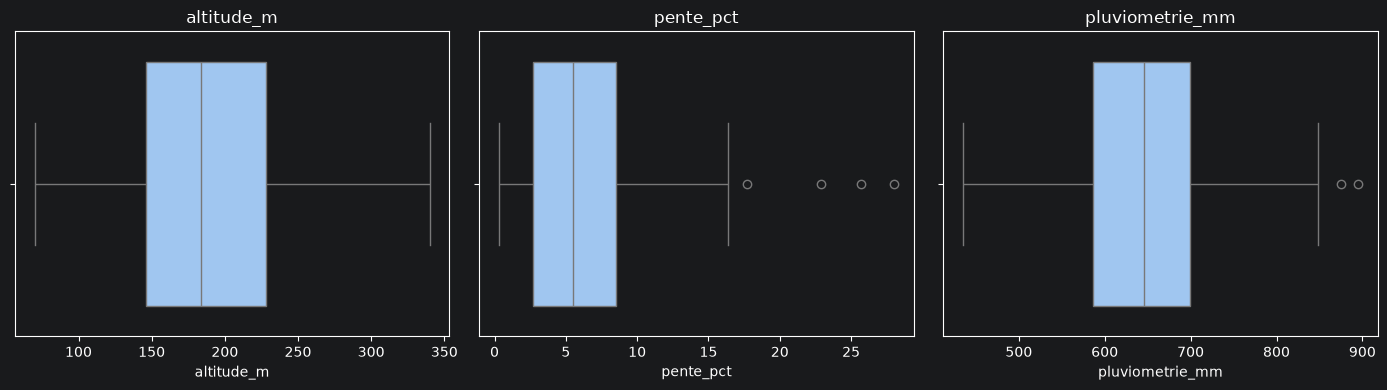

 altitude_m : seuils [22.6 ; 351.6] -> 0 parcelles au-delà
 pente_pct : seuils [-6.0 ; 17.3] -> 4 parcelles au-delà
 pluviometrie_mm : seuils [416.5 ; 868.5] -> 2 parcelles au-delà


In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, num_terroir):
    sns.boxplot(x=df[col], ax=ax, color="#93c5fd")
    ax.set_title(col)
plt.tight_layout()
plt.show()

for col in num_terroir:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    seuil_bas = q1 - 1.5 * iqr
    seuil_haut = q3 + 1.5 * iqr
    
    extremes = df[(df[col] < seuil_bas) | (df[col] > seuil_haut)]
    print(f" {col} : seuils [{seuil_bas:.1f} ; {seuil_haut:.1f}] -> {len(extremes)} parcelles au-delà")
    

Maintenant, on compare nos variables de terroir entre elles, on regarde si chaque type de sol, chaque exposition correspond déjà à une altitude, une pente ou une pluie particulière.
On découpe aussi l'altitude et la pente en tranches simples pour repérer des écarts qu'une moyenne globale écraserait.

In [24]:
print("Moyennes du terroir par type de sol")
display(df.groupby("type_sol")[num_terroir].mean().round(1))

print("Moyennes du terroir par exposition")
display(df.groupby("exposition")[num_terroir].mean().round(1))

print("Croisement type de sol x exposition")
display(pd.crosstab(df["type_sol"], df["exposition"], margins=True))

df_temp = df.copy()
df_temp["tranche_altitude"] = pd.cut(
    df_temp["altitude_m"],
    bins=[0, 140, 185, 230, 400],
    labels=["< 140 m", "140 - 185 m", "185 - 230 m", "> 230 m"]
)
df_temp["tranche_pente"] = pd.cut(
    df_temp["pente_pct"],
    bins=[0, 3, 6, 10, 35],
    labels=["Plat (< 3%)", "Doux (3-6%)", "Coteau (6-10%)", "Fort (> 10%)"]
)

print("Répartition des sols (%) par tranche d'altitude")
display((pd.crosstab(df_temp["tranche_altitude"], df_temp["type_sol"], normalize="index") * 100).round(1))

print("Répartition des sols (%) par tranche de pente")
display((pd.crosstab(df_temp["tranche_pente"], df_temp["type_sol"], normalize="index") * 100).round(1))

Moyennes du terroir par type de sol


,altitude_m,pente_pct,pluviometrie_mm
type_sol,,,
argilo-calcaire,182.8,6.9,659.3
caillouteux,182.0,5.8,636.1
limoneux,196.4,6.0,635.7
sableux,184.0,6.7,632.9


Moyennes du terroir par exposition


,altitude_m,pente_pct,pluviometrie_mm
exposition,,,
est,188.5,5.8,641.9
nord,175.9,6.2,633.2
sud,186.4,5.6,639.9
sud-est,184.4,7.6,644.0


Croisement type de sol x exposition


exposition,est,nord,sud,sud-est,All
type_sol,,,,,
argilo-calcaire,10,5,26,22,63
caillouteux,12,6,17,17,52
limoneux,11,2,15,13,41
sableux,19,8,16,13,56
All,52,21,74,65,212


Répartition des sols (%) par tranche d'altitude


type_sol,argilo-calcaire,caillouteux,limoneux,sableux
tranche_altitude,,,,
< 140 m,23.4,29.8,17.0,29.8
140 - 185 m,40.9,16.7,15.2,27.3
185 - 230 m,31.5,24.1,14.8,29.6
> 230 m,26.4,26.4,28.3,18.9


Répartition des sols (%) par tranche de pente


type_sol,argilo-calcaire,caillouteux,limoneux,sableux
tranche_pente,,,,
Plat (< 3%),30.6,29.0,16.1,24.2
Doux (3-6%),28.1,28.1,21.1,22.8
Coteau (6-10%),31.2,18.8,21.9,28.1
Fort (> 10%),37.8,16.2,13.5,32.4


,altitude_m,pente_pct,pluviometrie_mm,est_ouest_km,nord_sud_km,rendement_kg_ha
altitude_m,1.00,-0.04,0.02,0.07,0.08,-0.21
pente_pct,-0.04,1.00,-0.13,-0.01,0.09,-0.34
pluviometrie_mm,0.02,-0.13,1.00,-0.06,-0.11,0.38
est_ouest_km,0.07,-0.01,-0.06,1.00,0.06,0.07
nord_sud_km,0.08,0.09,-0.11,0.06,1.00,-0.09
rendement_kg_ha,-0.21,-0.34,0.38,0.07,-0.09,1.00


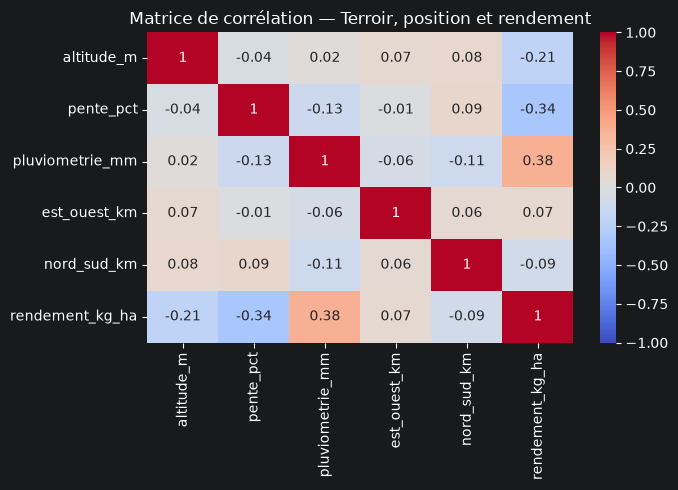

In [25]:
df_valide = df[~df["rendement_nul_a_verifier"]]

cols_corr = ["altitude_m", "pente_pct", "pluviometrie_mm", "est_ouest_km", "nord_sud_km", "rendement_kg_ha"]
mat_corr = df_valide[cols_corr].corr().round(2)

display(mat_corr)

plt.figure(figsize=(7, 5))
sns.heatmap(mat_corr, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Matrice de corrélation — Terroir, position et rendement")
plt.tight_layout()
plt.show()

Après analyse de ces données, voici mes hypothèses avant de lancer un algorithme :

H1: Je pense qu'un terroir ne dépend pas que du type de sol, mais d'un mélange de critères indépendants. On peut voir que les moyennes d'altitude (182 à 196 m), de pente (5,8 à 6,9 %) et de pluie (633 à 659 mm) bougent très peu selon le sol, et leurs corrélations entre elles sont quasi nulles (-0,13 à +0,02). Donc je garde les 5 variables de terroir dans le clustering pour voir ce qui sépare vraiment les groupes.   

H2: Je pense que le relief et la pluie jouent un vrai rôle et que les parcelles très pentues sont un profil à part, pas des erreurs car la pente est tirée vers le haut (moyenne à 6,4 % contre 5,5 % en médiane, avec 4 parcelles au-delà de 17,3 %), et la pluie (+0,38), la pente (-0,34) et l'altitude (-0,21) sont toutes liées au rendement donc je conserve ces valeurs extrêmes pour voir si le clustering les isole ou les rattache à un groupe.   

H3: Je pense que les terroirs ne suivent pas la carte géographique et se résument à 3 ou 4 grands profils car les corrélations avec la position (est_ouest_km, nord_sud_km) sont presque nulles (-0,11 à +0,09), les 4 sols sont bien répartis (18,6 % à 31,4 %) et plus de 63 % des parcelles sont exposées sud ou sud-est, je vais tester plusieurs nombres de clusters pour retenir le découpage le plus clair.

Je cherche à regrouper les parcelles selon leur terroir sans avoir de réponse connue à l'avance : c'est un problème non supervisé, j'utilise donc l'algorithme k-means vu en cours. Je laisse volontairement le rendement, le classement et la conduite (densité, azote, traitements) en dehors du calcul pour ne pas fausser les terroirs.Comme k-means calcule des distances sur des valeurs numériques, je travaille sur les 3 variables chiffrées du terroir (altitude_m, pente_pct, pluviometrie_mm) et je vérifierai ensuite le lien avec le type de sol et l'exposition.

Comme la pluie n'est presque pas liée à la position (-0,06 et -0,11) ni à l'altitude (0,02), je remplace simplement les 8 valeurs manquantes par la médiane (646 mm).

Je standardise les 3 colonnes avec StandardScaler pour qu'elles aient toutes une moyenne de 0 et un écart-type de 1 sinon la pluie (435 à 895 mm) et l'altitude (70 à 340 m) écraseraient la pente (0,3 à 28 %) dans le calcul des distances. Il n'y a pas de découpage apprentissage/test en non supervisé, donc je standardise tout le tableau directement.

In [26]:
from sklearn.preprocessing import StandardScaler

colonnes_terroir = ["altitude_m", "pente_pct", "pluviometrie_mm"]

df_km = df[colonnes_terroir].copy()
df_km["pluviometrie_mm"] = df_km["pluviometrie_mm"].fillna(df_km["pluviometrie_mm"].median())

X = StandardScaler().fit_transform(df_km)

print("Moyennes après standardisation :", X.mean(axis=0).round(3))
print("Écarts-types après standardisation :", X.std(axis=0).round(3))

Moyennes après standardisation : [-0. -0.  0.]
Écarts-types après standardisation : [1. 1. 1.]


Comme k-means impose de fixer k à l'avance, je teste plusieurs découpages avec n_init=10 (10 lancements pour garder l'inertie la plus basse). Pour choisir k, je croise la méthode du coude 
(k=1 à 8, via l'inertie et son gain d'un k au suivant) pour la compacité, 
et le score de silhouette (k=2 à 8, proche de 1) pour la séparation.

,k,inertie,gain_inertie,silhouette
0,1,660.0,NaN,NaN
1,2,495.9,164.1,0.245
2,3,386.1,109.8,0.259
3,4,303.0,83.0,0.267
4,5,262.9,40.1,0.259
5,6,233.2,29.8,0.270
6,7,209.0,24.2,0.275
7,8,195.7,13.3,0.274


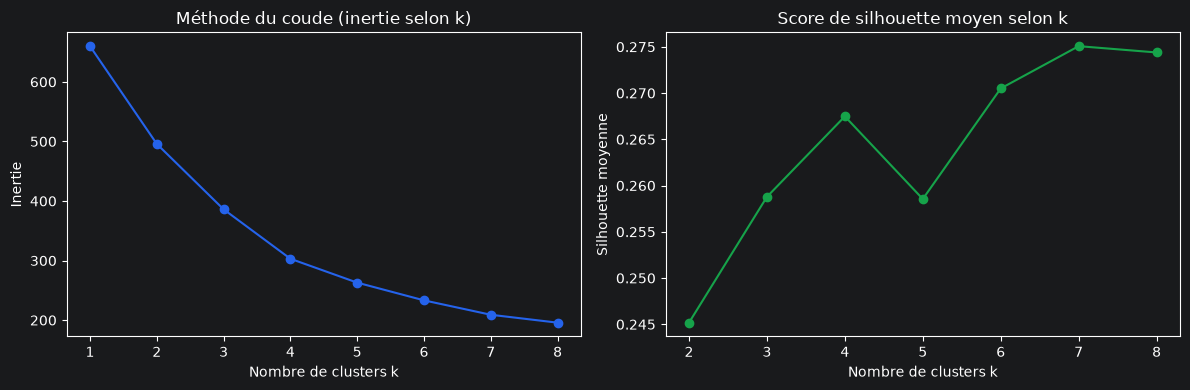

In [28]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import numpy as np

inerties = []
for k in range(1, 9):
    modele = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inerties.append(modele.inertia_)

gains = [np.nan] + [inerties[i - 1] - inerties[i] for i in range(1, len(inerties))]

silhouettes = [np.nan]
for k in range(2, 9):
    etiquettes = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)
    silhouettes.append(silhouette_score(X, etiquettes))

res_k = pd.DataFrame({
    "k": range(1, 9),
    "inertie": np.round(inerties, 1),
    "gain_inertie": np.round(gains, 1),
    "silhouette": np.round(silhouettes, 3)
})
display(res_k)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(range(1, 9), inerties, marker="o", color="#2563eb")
axes[0].set_title("Méthode du coude (inertie selon k)")
axes[0].set_xlabel("Nombre de clusters k")
axes[0].set_ylabel("Inertie")

axes[1].plot(range(2, 9), silhouettes[1:], marker="o", color="#16a34a")
axes[1].set_title("Score de silhouette moyen selon k")
axes[1].set_xlabel("Nombre de clusters k")
axes[1].set_ylabel("Silhouette moyenne")

plt.tight_layout()
plt.show()

La méthode du coude désigne k = 4, le gain d'inertie chute de moitié juste après (de 83,0 à 40,1), donc ajouter des groupes ne fait presque plus gagner de compacité. Le score de silhouette reste modeste (0,245 à 0,275), ce qui indique un terrain continu plutôt que des blocs totalement isolés. Il atteint toutefois un premier pic à k = 4 (0,267) avant de redescendre à k = 5 (0,259), même si k = 7 monte légèrement (0,275), je retiens 4 terroirs, un découpage cohérent et gérable sur le domaine. 

Je calcule maintenant le profil de chaque terroir sur les valeurs d'origine (non standardisées), puis je regarde après coup comment le sol, l'exposition, le rendement et le classement se répartissent dans chaque groupe.

In [ ]:
from sklearn.metrics import silhouette_samples


modele_final = KMeans(n_clusters=4, n_init=10, random_state=42)
df["terroir"] = modele_final.fit_predict(X)


df["silhouette_parcelle"] = silhouette_samples(X, df["terroir"])
print("Parcelles à la frontière (silhouette < 0) :", (df["silhouette_parcelle"] < 0).sum(), "sur", len(df))

profil_num = df.groupby("terroir")[colonnes_terroir].mean().round(1)
profil_num.insert(0, "nb_parcelles", df["terroir"].value_counts().sort_index())

df_valide = df[~df["rendement_nul_a_verifier"]].copy()
profil_num["rendement_moy"] = df_valide.groupby("terroir")["rendement_kg_ha"].mean().round(0)
profil_num["part_premium_%"] = (
    df_valide.groupby("terroir")["classement_recolte"]
    .apply(lambda s: (s == "premium").mean() * 100)
    .round(1)
)

print("Profil des 4 terroirs (valeurs d'origine)")
display(profil_num)

# 4. Regard après coup sur type_sol et exposition (%)
print("Répartition des sols (%) par terroir")
display((pd.crosstab(df["terroir"], df["type_sol"], normalize="index") * 100).round(1))

print("Répartition des expositions (%) par terroir")
display((pd.crosstab(df["terroir"], df["exposition"], normalize="index") * 100).round(1))

In [29]:
noms_terroirs = {
    0: "Hauts plateaux secs",
    1: "Basses plaines sèches",
    2: "Coteaux pentus",
    3: "Terres humides"
}
df["nom_terroir"] = df["terroir"].map(noms_terroirs)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(
    data=df, x="altitude_m", y="pente_pct",
    hue="nom_terroir", palette="Set2", s=60, ax=axes[0]
)
axes[0].set_title("Altitude vs Pente selon le terroir")

sns.scatterplot(
    data=df, x="pluviometrie_mm", y="pente_pct",
    hue="nom_terroir", palette="Set2", s=60, ax=axes[1]
)
axes[1].set_title("Pluviométrie vs Pente selon le terroir")

plt.tight_layout()
plt.show()

df_valide = df[~df["rendement_nul_a_verifier"]]
bilan = df.groupby("nom_terroir")[colonnes_terroir].mean().round(1)
bilan.insert(0, "nb_parcelles", df["nom_terroir"].value_counts())
bilan["rendement_moy"] = df_valide.groupby("nom_terroir")["rendement_kg_ha"].mean().round(0)
bilan["part_premium_%"] = (
    df_valide.groupby("nom_terroir")["classement_recolte"]
    .apply(lambda s: (s == "premium").mean() * 100)
    .round(1)
)
display(bilan.sort_values("part_premium_%", ascending=False))

df.to_csv("../data/processed/parcelles_terroirs.csv", index=False)
print("Fichier sauvegardé : ../data/processed/parcelles_terroirs.csv")

KeyError: 'terroir'

Bilan des hypothèses Q7 :

    H1 validée : tous les sols se retrouvent dans chaque groupe ; c'est bien le relief et la pluie qui séparent les terroirs.   
    H2 validée : les fortes pentes forment un vrai terroir à part (Coteaux pentus), le plus qualitatif du domaine.   
    H3 validée : le domaine se résume à 4 grands terroirs clairs et exploitables pour adapter la conduite

Question 8 — Pour chaque type, quelle conduite — densité, apports, traitements ?

Je repars des 4 terroirs identifiés à la question 7 (parcelles_terroirs.csv) pour analyser les pratiques de conduite et voir comment optimiser le rendement et la qualité (premium) sur chaque groupe. Je commence par vérifier le tableau enrichi et les éventuelles valeurs manquantes.

In [ ]:
df = pd.read_csv("../data/processed/parcelles_terroirs.csv")
print("Dimensions :", df.shape)
print("Colonnes :", list(df.columns))

print("\nValeurs manquantes par colonne :")
display(df.isna().sum()[df.isna().sum() > 0])

display(df.head())